# Temperature and Humidity Analysis

This is my Phase 1 project using the readings collected from my DHT22 sensor and ESP32. The data was stored in Firebase and then exported as a CSV file.

In this notebook, I will clean the data, understand the temperature and humidity patterns, and try different regression models to predict the next 10-minute reading.

This phase has around 26 hours of data, so I am treating the results as an initial experiment. I will compare them with the data collected in the next phases.

## 1. Import libraries

First, I will import the libraries needed for data handling, graphs and machine learning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
plt.style.use("ggplot")

## 2. Load the dataset

I am loading the CSV file here. I also check whether the required columns are available before moving ahead.

In [2]:
data_path = Path("DHT22_Dataset.csv")

if not data_path.exists():
    data_path = Path("Phase_1") / "DHT22_Dataset.csv"

if not data_path.exists():
    raise FileNotFoundError("DHT22_Dataset.csv was not found. Run this notebook from the project folder or Phase_1.")

raw_data = pd.read_csv(data_path)
raw_data.columns = raw_data.columns.str.strip().str.lower()

required_columns = {"record_id", "humidity", "status", "temperature", "timestamp"}
missing_columns = required_columns.difference(raw_data.columns)

if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

print("Dataset shape:", raw_data.shape)
display(raw_data.head())
raw_data.info()


Dataset shape: (45357, 5)


,record_id,humidity,status,temperature,timestamp
0,-P5IFbPjVBBKnoXF4LIa,78.3,True,32.4,1793471968000
1,-P5IFbuXNOwMuNxskJxE,78.3,True,32.4,1793471970000
2,-P5IFcPo9iXCVoKarjnr,78.3,True,32.4,1793471972000
3,-P5IFcv3NY37CUogbb0P,78.3,True,32.4,1793471974000
4,-P5IFdM6GPXfNtlyrV-R,78.3,True,32.4,1793471976000


<class 'pandas.DataFrame'>
RangeIndex: 45357 entries, 0 to 45356
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   record_id    45357 non-null  str    
 1   humidity     45270 non-null  float64
 2   status       45357 non-null  bool   
 3   temperature  45270 non-null  float64
 4   timestamp    45357 non-null  int64  
dtypes: bool(1), float64(2), int64(1), str(1)
memory usage: 1.4 MB


## 3. Check and clean the data

Before doing the analysis, I want to check missing values, sensor status and duplicate timestamps.

I will keep successful readings only. I will also remove rows where the timestamp, temperature or humidity is missing. If a timestamp is repeated, I will keep the last reading.

In [3]:
print("Missing values:")
display(raw_data.isnull().sum())

print("\nSensor status:")
display(raw_data["status"].value_counts(dropna=False))

print("\nDuplicate timestamps:", raw_data["timestamp"].duplicated().sum())

Missing values:


record_id       0
humidity       87
status          0
temperature    87
timestamp       0
dtype: int64


Sensor status:


status
True     45270
False       87
Name: count, dtype: int64


Duplicate timestamps: 14


In [4]:
data = raw_data.copy()

# Convert sensor values and timestamp to numeric values
data["temperature"] = pd.to_numeric(data["temperature"], errors="coerce")
data["humidity"] = pd.to_numeric(data["humidity"], errors="coerce")
data["timestamp"] = pd.to_numeric(data["timestamp"], errors="coerce")

# Keep readings where the sensor status is True
data["status_ok"] = data["status"].astype(str).str.strip().str.lower() == "true"

# Convert Firebase timestamp from milliseconds to Indian time
data["date_time"] = pd.to_datetime(
    data["timestamp"], unit="ms", utc=True, errors="coerce"
).dt.tz_convert("Asia/Kolkata")

# Remove failed or incomplete readings
clean_data = data[
    (data["status_ok"]) &
    (data["date_time"].notna()) &
    (data["temperature"].notna()) &
    (data["humidity"].notna())
].copy()

# Remove duplicate timestamps and keep the last reading
duplicate_count = clean_data["date_time"].duplicated().sum()
clean_data = clean_data.sort_values("date_time")
clean_data = clean_data.drop_duplicates(subset="date_time", keep="last")
clean_data = clean_data.reset_index(drop=True)

# Save the cleaned data
output_path = data_path.parent / "clean_HT.csv"
clean_data[["record_id", "date_time", "temperature", "humidity"]].to_csv(
    output_path, index=False
)

print("Total records:", len(raw_data))
print("Failed readings:", int((~data["status_ok"]).sum()))
print("Repeated timestamps removed:", duplicate_count)
print("Clean records:", len(clean_data))
print("Data starts:", clean_data["date_time"].min())
print("Data ends:", clean_data["date_time"].max())

display(clean_data[["date_time", "temperature", "humidity"]].head())

Total records: 45357
Failed readings: 87
Repeated timestamps removed: 14
Clean records: 45256
Data starts: 2026-11-01 00:09:28+05:30
Data ends: 2026-11-02 02:22:41+05:30


,date_time,temperature,humidity
0,2026-11-01 00:09:28+05:30,32.4,78.3
1,2026-11-01 00:09:30+05:30,32.4,78.3
2,2026-11-01 00:09:32+05:30,32.4,78.3
3,2026-11-01 00:09:34+05:30,32.4,78.3
4,2026-11-01 00:09:36+05:30,32.4,78.3


## 4. Explore the readings

Now I will get a basic idea of the data using summary statistics and graphs.

I will check the temperature and humidity distributions, see how they are related, and look at how the readings change over time.

In [5]:
display(clean_data[["temperature", "humidity"]].describe().T)


,count,mean,std,min,25%,50%,75%,max
temperature,45256.0,31.328584,1.061938,29.5,30.3,31.2,32.4,33.1
humidity,45256.0,72.907975,2.782659,67.5,70.4,72.5,75.6,79.5


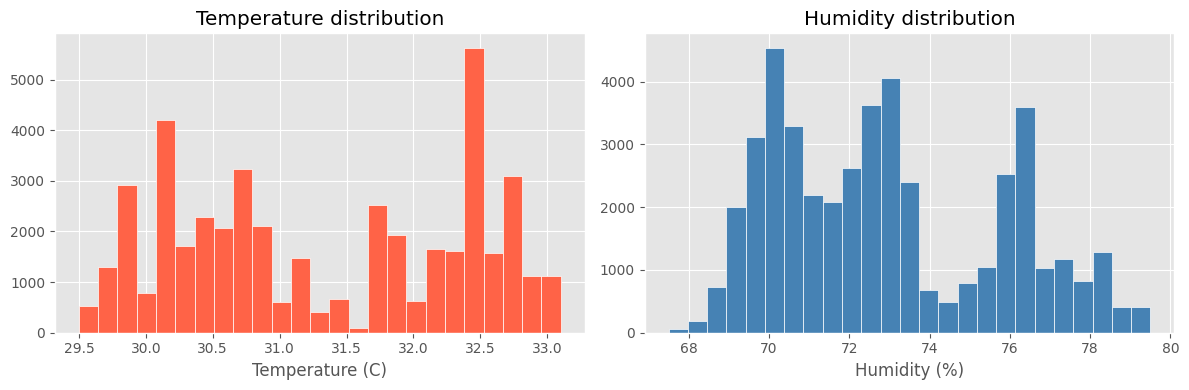

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(clean_data["temperature"], bins=25, color="tomato", edgecolor="white")
axes[0].set_title("Temperature distribution")
axes[0].set_xlabel("Temperature (C)")

axes[1].hist(clean_data["humidity"], bins=25, color="steelblue", edgecolor="white")
axes[1].set_title("Humidity distribution")
axes[1].set_xlabel("Humidity (%)")

plt.tight_layout()
plt.show()


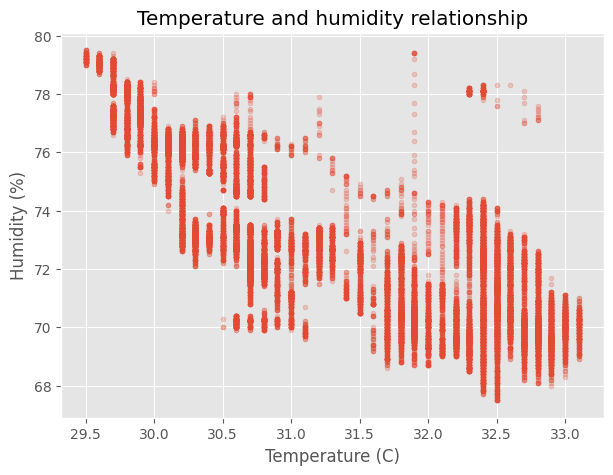

Correlation between temperature and humidity:


,temperature,humidity
temperature,1.000000,-0.811472
humidity,-0.811472,1.000000


In [7]:
plt.figure(figsize=(7, 5))
plt.scatter(clean_data["temperature"], clean_data["humidity"], alpha=0.25, s=12)
plt.title("Temperature and humidity relationship")
plt.xlabel("Temperature (C)")
plt.ylabel("Humidity (%)")
plt.show()

print("Correlation between temperature and humidity:")
display(clean_data[["temperature", "humidity"]].corr())


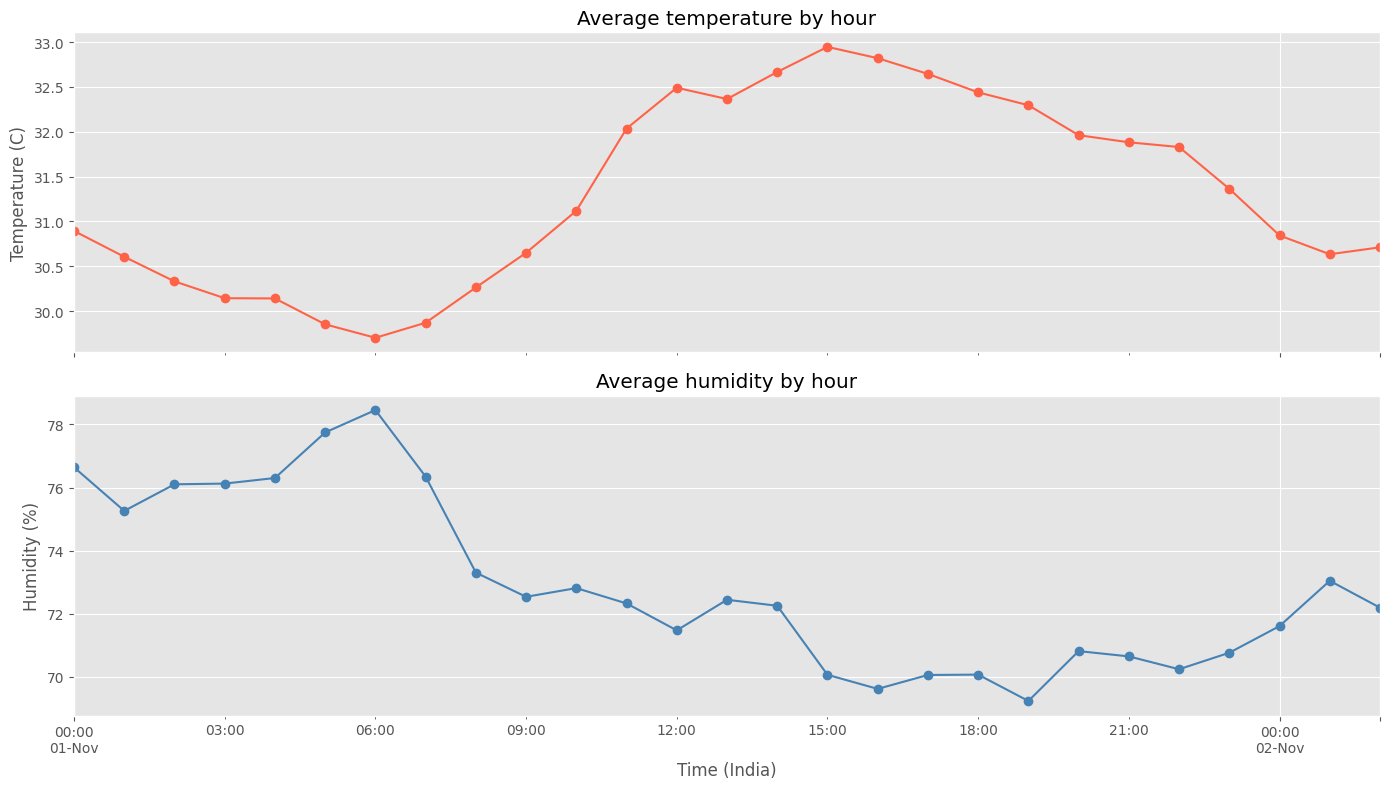

In [8]:
time_data = clean_data.set_index("date_time")
hourly_data = time_data[["temperature", "humidity"]].resample("1h").mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
hourly_data["temperature"].plot(ax=axes[0], color="tomato", marker="o")
axes[0].set_title("Average temperature by hour")
axes[0].set_ylabel("Temperature (C)")

hourly_data["humidity"].plot(ax=axes[1], color="steelblue", marker="o")
axes[1].set_title("Average humidity by hour")
axes[1].set_ylabel("Humidity (%)")
axes[1].set_xlabel("Time (India)")

plt.tight_layout()
plt.show()


## 5. Prepare data for prediction

The sensor records readings very frequently, so I will group them into 10-minute intervals and use the median value for each interval.

For prediction, I will use the current reading, the previous two readings and the time of day. The target will be the next 10-minute reading.

I will keep the data in time order. The first 80% will be used for training and the remaining 20% for testing.

In [9]:
# Group the readings into 10-minute intervals
window_data = (
    clean_data.set_index("date_time")[["temperature", "humidity"]]
    .resample("10min", origin="start")
    .median()
    .dropna()
)

# Keep only intervals that have a complete 10-minute window
last_time = clean_data["date_time"].max()
window_data = window_data[
    window_data.index + pd.Timedelta(minutes=10) <= last_time
]

print("Number of 10-minute intervals:", len(window_data))
display(window_data.head())

Number of 10-minute intervals: 157


,temperature,humidity
date_time,,
2026-11-01 00:09:28+05:30,32.3,78.1
2026-11-01 00:19:28+05:30,30.7,76.5
2026-11-01 00:29:28+05:30,30.6,76.4
2026-11-01 00:39:28+05:30,30.5,76.6
2026-11-01 00:49:28+05:30,30.5,76.3


In [10]:
forecast_data = window_data.copy()
forecast_data["temperature_lag_1"] = window_data["temperature"].shift(1)
forecast_data["humidity_lag_1"] = window_data["humidity"].shift(1)
forecast_data["temperature_lag_2"] = window_data["temperature"].shift(2)
forecast_data["humidity_lag_2"] = window_data["humidity"].shift(2)

next_time = forecast_data.index + pd.Timedelta(minutes=10)
hour_of_day = next_time.hour + next_time.minute / 60
forecast_data["hour_sin"] = np.sin(2 * np.pi * hour_of_day / 24)
forecast_data["hour_cos"] = np.cos(2 * np.pi * hour_of_day / 24)

forecast_data["temperature_next"] = window_data["temperature"].shift(-1)
forecast_data["humidity_next"] = window_data["humidity"].shift(-1)

feature_columns = [
    "temperature", "humidity",
    "temperature_lag_1", "humidity_lag_1",
    "temperature_lag_2", "humidity_lag_2",
    "hour_sin", "hour_cos"
]
target_columns = ["temperature_next", "humidity_next"]

forecast_data = forecast_data.dropna(subset=feature_columns + target_columns)
X = forecast_data[feature_columns]
y = forecast_data[target_columns]

split_point = int(len(forecast_data) * 0.8)
if split_point == 0 or split_point == len(forecast_data):
    raise ValueError("There are not enough 10-minute windows for a chronological train/test split.")

X_train, X_test = X.iloc[:split_point], X.iloc[split_point:]
y_train, y_test = y.iloc[:split_point], y.iloc[split_point:]

print("Training windows:", len(X_train))
print("Testing windows:", len(X_test))
print("Training period:", forecast_data.index[0], "to", forecast_data.index[split_point - 1])
print("Testing period:", forecast_data.index[split_point], "to", forecast_data.index[-1])


Training windows: 123
Testing windows: 31
Training period: 2026-11-01 00:29:28+05:30 to 2026-11-01 20:49:28+05:30
Testing period: 2026-11-01 20:59:28+05:30 to 2026-11-02 01:59:28+05:30


## 6. Train the models

I will compare different regression models and also include a simple baseline.

The baseline assumes that the next reading will be the same as the current reading. This helps me check whether the ML models are actually improving the prediction.

I am using Linear Regression, Polynomial Regression, Decision Tree, Random Forest, KNN and SVR.

In [11]:
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=8, random_state=42, n_jobs=-1
    ),
    "K-Nearest Neighbors": make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5)
    ),
    "Support Vector Regression": make_pipeline(
        StandardScaler(),
        MultiOutputRegressor(SVR())
    )
}

predictions = {}
score_rows = []

# The current window is the simple persistence prediction for the next window.
predictions["Persistence baseline"] = X_test[["temperature", "humidity"]].to_numpy()

for model_name, model in models.items():
    model.fit(X_train, y_train)
    predictions[model_name] = model.predict(X_test)

for model_name, y_pred in predictions.items():
    for column_number, target_name in enumerate(target_columns):
        actual = y_test.iloc[:, column_number]
        predicted = y_pred[:, column_number]
        mse = mean_squared_error(actual, predicted)
        score_rows.append({
            "model": model_name,
            "target": target_name.replace("_next", ""),
            "MAE": mean_absolute_error(actual, predicted),
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R2": r2_score(actual, predicted)
        })

scores = pd.DataFrame(score_rows)
scores = scores.sort_values(["target", "MAE"]).reset_index(drop=True)
display(scores.round(3))


,model,target,MAE,MSE,RMSE,R2
0,Persistence baseline,humidity,0.682,0.867,0.931,0.463
1,Linear Regression,humidity,0.740,1.072,1.035,0.336
2,Random Forest,humidity,1.116,1.758,1.326,-0.089
3,Support Vector Regression,humidity,1.340,2.446,1.564,-0.515
4,K-Nearest Neighbors,humidity,1.457,3.094,1.759,-0.916
5,Decision Tree,humidity,1.745,4.535,2.129,-1.809
6,Polynomial Regression,humidity,1.962,4.985,2.233,-2.088
7,Persistence baseline,temperature,0.113,0.025,0.160,0.919
8,Linear Regression,temperature,0.127,0.028,0.167,0.911
9,Support Vector Regression,temperature,0.212,0.062,0.248,0.804


## 7. Compare model results

I will compare the models using MAE, MSE, RMSE and R-squared.

For MAE, MSE and RMSE, lower values are better. For R-squared, a value closer to 1 generally indicates a better fit.

I will also plot the actual and predicted values for the best model for each target.

Best model for temperature by test MAE: Persistence baseline
Best model for humidity by test MAE: Persistence baseline


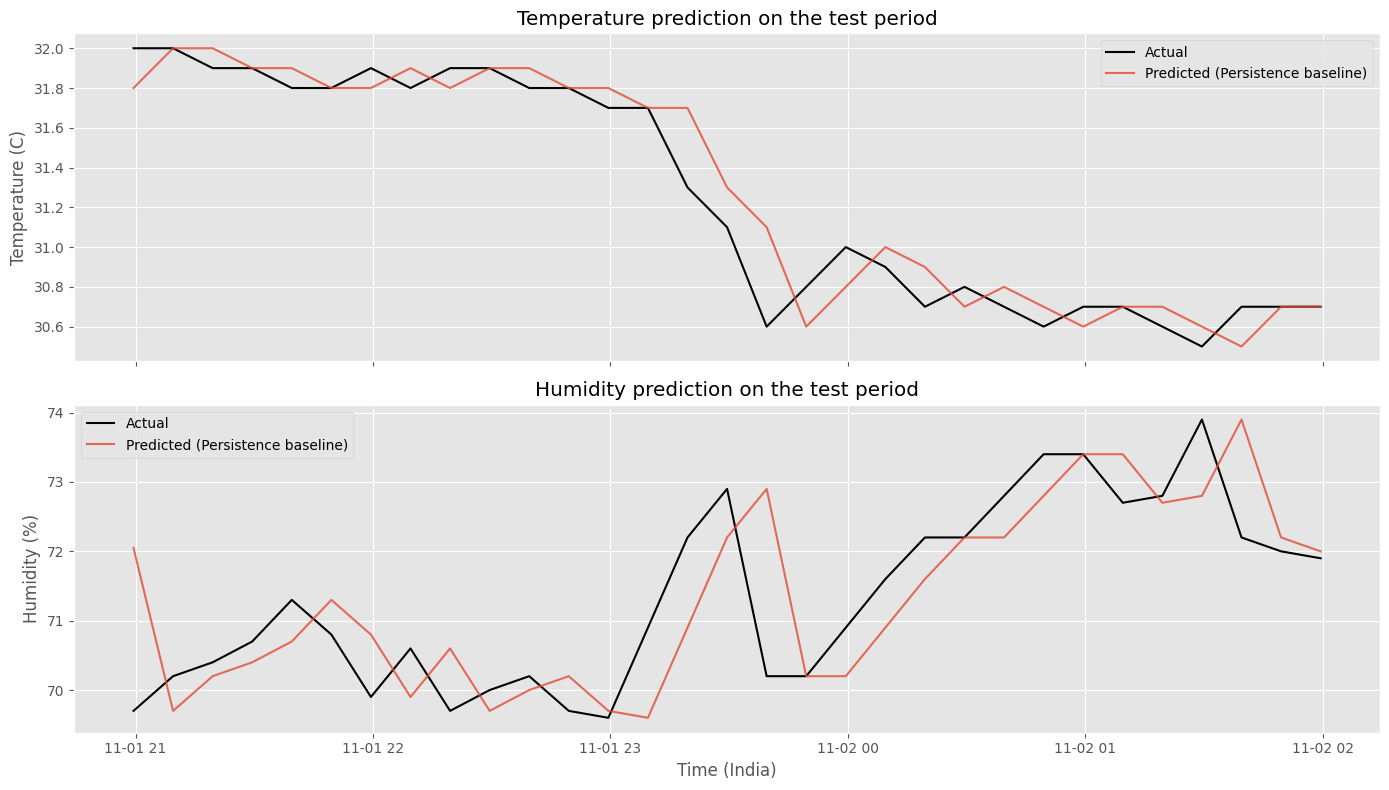

In [12]:
best_models = {}

for target_name in ["temperature", "humidity"]:
    best_model = (
        scores[scores["target"] == target_name]
        .sort_values("MAE")
        .iloc[0]["model"]
    )
    best_models[target_name] = best_model
    print(f"Best model for {target_name} by test MAE: {best_model}")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

for axis, target_name, target_column in zip(
    axes,
    ["temperature", "humidity"],
    target_columns
):
    column_number = target_columns.index(target_column)
    axis.plot(y_test.index, y_test[target_column], label="Actual", color="black")
    axis.plot(
        y_test.index,
        predictions[best_models[target_name]][:, column_number],
        label=f"Predicted ({best_models[target_name]})",
        alpha=0.8
    )
    axis.set_title(f"{target_name.title()} prediction on the test period")
    axis.set_ylabel("Temperature (C)" if target_name == "temperature" else "Humidity (%)")
    axis.legend()

axes[-1].set_xlabel("Time (India)")
plt.tight_layout()
plt.show()


In [13]:
# Show the best result for temperature and humidity
best_results = []

for target in ["temperature", "humidity"]:
    result = scores[scores["target"] == target].sort_values("MAE").iloc[0]
    best_results.append(result)

best_results = pd.DataFrame(best_results)

display(best_results[["target", "model", "MAE", "RMSE", "R2"]].round(3))

print("These results are from the Phase 1 dataset only.")
print("I will compare them with Phase 2 and Phase 3 after collecting more data.")

,target,model,MAE,RMSE,R2
7,temperature,Persistence baseline,0.113,0.160,0.919
0,humidity,Persistence baseline,0.682,0.931,0.463


These results are from the Phase 1 dataset only.
I will compare them with Phase 2 and Phase 3 after collecting more data.


## 8. What I found

These results are based only on my Phase 1 data and the next-10-minute prediction setup. This is a short collection period, so I cannot use these results to make strong claims about future performance.

I will collect more readings in Phase 2 and Phase 3 and compare the results using the same approach.